In [1]:
import sys, sklearn, ipykernel
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
print(sys.version)
print(sys.executable)
print("Setup OK!")

print('test data cleaning')

print('hi')

3.14.9 (v3.14.9:ead82c07db1, Oct 20 2026, 23:27:28) [Clang 21.0.0 (clang-2100.1.1.101)]
/Users/nikolanikolov/Documents/GitHub/ml-group-project/.venv/bin/python
Setup OK!
test data cleaning
hi


In [2]:
df = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)
IDS_mapping = pd.read_csv('IDS_mapping.csv', na_values = ['?'], keep_default_na = False)

/var/folders/wy/ymq6dx6n0z76tgh43whw2dxr0000gn/T/ipykernel_57195/2389660198.py:1: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('diabetic_data.csv',  na_values = ['?'], keep_default_na = False)


In [3]:
diabetic_data_1 = diabetic_data.drop(columns = ['discharge_disposition_id', 'encounter_id'])

NameError: name 'diabetic_data' is not defined

In [ ]:
diabetic_data_2 = diabetic_data_1.drop(columns = ['weight', 'payer_code', 'race'])
diabetic_data_2.shape

(101766, 45)

In [ ]:
diabetic_data_3 = diabetic_data_2.drop(diabetic_data_2[diabetic_data_2['gender'] == 'Unknown/Invalid'].index)
diabetic_data_3.shape 

(101763, 45)

In [ ]:
diabetic_data_3 = diabetic_data_3.drop(columns = ['examide', 'citoglipton'])
diabetic_data_3.shape

(101763, 43)

In [ ]:
#Nateglinide
print(diabetic_data_3['nateglinide'].value_counts(normalize= True))

#chlorpropamide
print(diabetic_data_3['chlorpropamide'].value_counts(normalize=True)) #>99.9

#acetohexamide
print(diabetic_data_3['acetohexamide'].value_counts(normalize=True)) #>99.9

#tolbutamide
print(diabetic_data_3['tolbutamide'].value_counts(normalize=True)) #>99.9

#acarbose
print(diabetic_data_3['acarbose'].value_counts(normalize=True)) 

#miglitol
print(diabetic_data_3['miglitol'].value_counts(normalize=True)) #>99.9

#troglitazone
print(diabetic_data_3['troglitazone'].value_counts(normalize=True)) #99.9

#tolazamide
print(diabetic_data_3['tolazamide'].value_counts(normalize=True)) #>99.9

#glyburide-metformin
print(diabetic_data_3['glyburide-metformin'].value_counts(normalize=True))

#glipizide-metformin
print(diabetic_data_3['glipizide-metformin'].value_counts(normalize=True)) #>99.9

#glimepiride-pioglitazone
print(diabetic_data_3['glimepiride-pioglitazone'].value_counts(normalize=True)) #>99.9

#metformin-rosiglitazone
print(diabetic_data_3['metformin-rosiglitazone'].value_counts(normalize=True)) #>99.9

#metformin-pioglitazone
print(diabetic_data_3['metformin-pioglitazone'].value_counts(normalize=True)) #>99.9



nateglinide
No        0.993092
Steady    0.006564
Up        0.000236
Down      0.000108
Name: proportion, dtype: float64
chlorpropamide
No        0.999155
Steady    0.000776
Up        0.000059
Down      0.000010
Name: proportion, dtype: float64
acetohexamide
No        0.99999
Steady    0.00001
Name: proportion, dtype: float64
tolbutamide
No        0.999774
Steady    0.000226
Name: proportion, dtype: float64
acarbose
No        0.996973
Steady    0.002899
Up        0.000098
Down      0.000029
Name: proportion, dtype: float64
miglitol
No        0.999627
Steady    0.000305
Down      0.000049
Up        0.000020
Name: proportion, dtype: float64
troglitazone
No        0.999971
Steady    0.000029
Name: proportion, dtype: float64
tolazamide
No        0.999617
Steady    0.000373
Up        0.000010
Name: proportion, dtype: float64
glyburide-metformin
No        0.993062
Steady    0.006800
Up        0.000079
Down      0.000059
Name: proportion, dtype: float64
glipizide-metformin
No        0.999872


In [ ]:
diabetic_data_4 = diabetic_data_3.drop(columns=['chlorpropamide', 'acetohexamide', 'tolbutamide',
 'miglitol', 'troglitazone','tolazamide', 'glipizide-metformin', 'glimepiride-pioglitazone','metformin-pioglitazone'    ])

diabetic_data_4.shape

(101763, 34)

<h1><u> Encoding </u></h1>
<h3>Encoding the 'gender', 'age' and 'admission_type_id'</h3>

<i>What is it for?</i> To turn text into numbers for the models to be able to work.





In [ ]:


diabetic_data_4['gender'] = diabetic_data_4['gender'].map({
    'Male': 0,
    'Female': 1
})


diabetic_data_4['admission_type_id'] = diabetic_data_4['admission_type_id'].replace({
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'unknown',
    6: 'unknown',
    8: 'unknown',
    7: 'Trauma Center'
})

<h3> admission_source_id encoding </h3>
The numbered values were changed into their description, so that one hot encoding could group them easily. Any value that did not have a count of over 100 went into the other category.

In [ ]:
print(diabetic_data_4['admission_source_id'].unique())
print(diabetic_data_4['admission_source_id'].value_counts)

diabetic_data_4['admission_source_id'] = diabetic_data_4['admission_source_id'].replace({
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a hospital',
    5: 'Transfer from a Skilled Nursing Facility (SNF)',
    6: 'Transfer from another health care facility',
    7: 'Emergency Room',
    8: 'other',
    9: 'unknown',
    10: 'other',
    11: 'other',
    12: 'Premature Delivery',
    13: 'other',
    14: 'other',
    15: 'unknown',
    16: 'unknown',
    17: 'unknown',
    18: 'Transfer From Another Home Health Agency',
    19: 'Readmission to Same Home Health Agency',
    20: 'unknown',
    21: 'unknown',
    22: 'other',
    23: 'Born inside this hopsital',
    24: 'Born outside this hospital',
    25: 'other',
    26: 'Transfer from Hospice'

})

[ 1  7  2  4  5  6 20  3 17  8  9 14 10 22 11 25 13]
<bound method IndexOpsMixin.value_counts of 0         1
1         7
2         7
3         7
4         7
         ..
101761    7
101762    5
101763    7
101764    7
101765    7
Name: admission_source_id, Length: 101763, dtype: int64>


<h3>Encoding medical_specialty</h3>

In [ ]:
print(diabetic_data_4['medical_specialty'].unique())
print(diabetic_data_4['medical_specialty'].value_counts)

diabetic_data_4['medical_specialty'] = diabetic_data_4['medical_specialty'].fillna('unknown')
diabetic_data_4['medical_specialty'] = diabetic_data_4['medical_specialty'].replace({
    'Surgery-General': 'surgery',
    'Surgery-Cardiovascular/Thoracic': 'surgery',
    'Surgery-Neuro': 'surgery',
    'Surgery-Colon&Rectal': 'surgery',
    'Surgery-Thoracic': 'surgery',
    'Surgery-Vascular': 'surgery',
    'Surgery-Plastic': 'surgery',
    'Surgery-Cardiovascular': 'surgery',
    'Surgery-Maxillofacial': 'surgery',
    'Surgery-Pediatric': 'surgery',
    'Surgery-PlasticwithinHeadandNeck': 'surgery'
})


<StringArray>
[            'Pediatrics-Endocrinology',
                                    nan,
                     'InternalMedicine',
               'Family/GeneralPractice',
                           'Cardiology',
                      'Surgery-General',
                          'Orthopedics',
                     'Gastroenterology',
      'Surgery-Cardiovascular/Thoracic',
                           'Nephrology',
           'Orthopedics-Reconstructive',
                           'Psychiatry',
                     'Emergency/Trauma',
                          'Pulmonology',
                        'Surgery-Neuro',
 'Obsterics&Gynecology-GynecologicOnco',
              'ObstetricsandGynecology',
                           'Pediatrics',
                  'Hematology/Oncology',
                       'Otolaryngology',
                 'Surgery-Colon&Rectal',
              'Pediatrics-CriticalCare',
                        'Endocrinology',
                              'Urology',
  

In [ ]:
categorical_columns = ['age', 'admission_type_id', 'admission_source_id']
diabetic_data_4 = pd.get_dummies(
    diabetic_data_4,
    columns = categorical_columns,
    dtype=int,
    drop_first=True
)

In [ ]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
female = diabetic_data_4[diabetic_data_4['gender'] == 'Female'].copy()

female.info

gender
1    54708
0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [patient_nbr, gender, time_in_hospital, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, glimepiride, glipizide, glyburide, pioglitazone, rosiglitazone, acarbose, insulin, glyburide-metformin, metformin-rosiglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_source_id_Emergency Room, admission_source_id_HMO Referral, admission_source_id_Physician Referral, admission_source_id_Transfer from a Skilled Nursing Facility (SNF), admission_source_id_Transfer from a hospital, admission_source_id_Trans

In [ ]:
print(diabetic_data_4['gender'].value_counts())
diabetic_data_4.groupby('gender')['time_in_hospital'].mean()
male = diabetic_data_4[diabetic_data_4['gender'] == 'Male'].copy()

male.info

gender
1    54708
0    47055
Name: count, dtype: int64


<bound method DataFrame.info of Empty DataFrame
Columns: [patient_nbr, gender, time_in_hospital, medical_specialty, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, diag_1, diag_2, diag_3, number_diagnoses, max_glu_serum, A1Cresult, metformin, repaglinide, nateglinide, glimepiride, glipizide, glyburide, pioglitazone, rosiglitazone, acarbose, insulin, glyburide-metformin, metformin-rosiglitazone, change, diabetesMed, readmitted, age_[10-20), age_[20-30), age_[30-40), age_[40-50), age_[50-60), age_[60-70), age_[70-80), age_[80-90), age_[90-100), admission_type_id_Emergency, admission_type_id_Newborn, admission_type_id_Trauma Center, admission_type_id_Urgent, admission_type_id_unknown, admission_source_id_Emergency Room, admission_source_id_HMO Referral, admission_source_id_Physician Referral, admission_source_id_Transfer from a Skilled Nursing Facility (SNF), admission_source_id_Transfer from a hospital, admission_source_id_Trans

In [ ]:
#Admission type id -> Time in hospital
admission_type_means = diabetic_data_4.groupby(['admission_type_id'])['time_in_hospital'].mean()

#Admissionn source id -> Time in hospital
admission_source_means = diabetic_data_4.groupby(['admission_source_id'])['time_in_hospital'].mean()

#Replacing the admission type id and admission source id with their descriptions
admission_type_means.index = admission_type_means.index.map(admission_type_descriptions)
admission_source_means.index = admission_source_means.index.map(admission_source_descriptions)

print(admission_type_means)
print(admission_source_means)

#Grouping admission type id with admission source id
admission_type_source_means = diabetic_data_4.groupby(['admission_type_id', 'admission_source_id'])['time_in_hospital'].mean()
admission_type_source_means.index = admission_type_source_means.index.map(lambda x: (admission_type_descriptions.get(x[0]), admission_source_descriptions.get(x[1])))

print(admission_type_source_means)


KeyError: 'admission_type_id'

In [ ]:
#ANOVA test to see what factors have a significant effect on the time in hospital
import statsmodels.api as sm

model = sm.OLS(diabetic_data_2['time_in_hospital'], sm.add_constant(diabetic_data_2[['admission_type_id', 'admission_source_id']])).fit()

print(model.summary())

#Determining significant factors based on p-values
significant_factors = model.pvalues[model.pvalues < 0.05].index
print(significant_factors)


                            OLS Regression Results                            
Dep. Variable:       time_in_hospital   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     9.584
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           6.89e-05
Time:                        06:31:10   Log-Likelihood:            -2.5568e+05
No. Observations:              101766   AIC:                         5.114e+05
Df Residuals:                  101763   BIC:                         5.114e+05
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   4.4698    

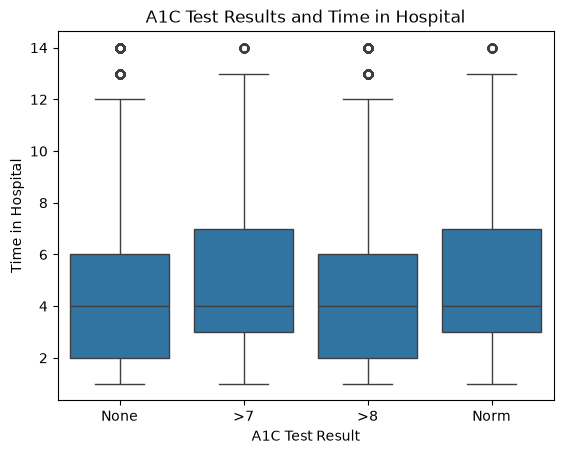

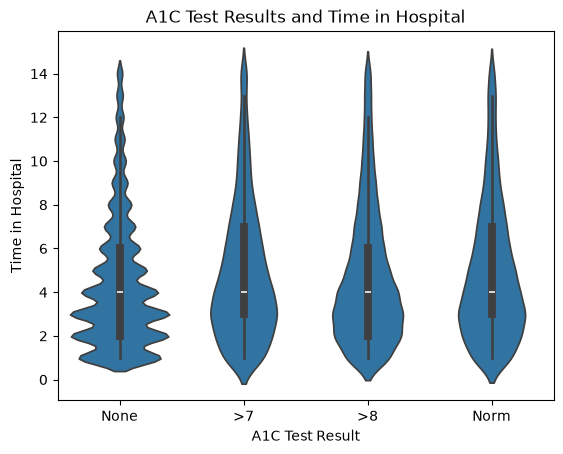

In [ ]:
#Generating a plot for A1C tests and time in hospital
sns.boxplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')

#Generating a violin plot
plt.figure()
sns.violinplot(data=diabetic_data_4, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')
plt.show()

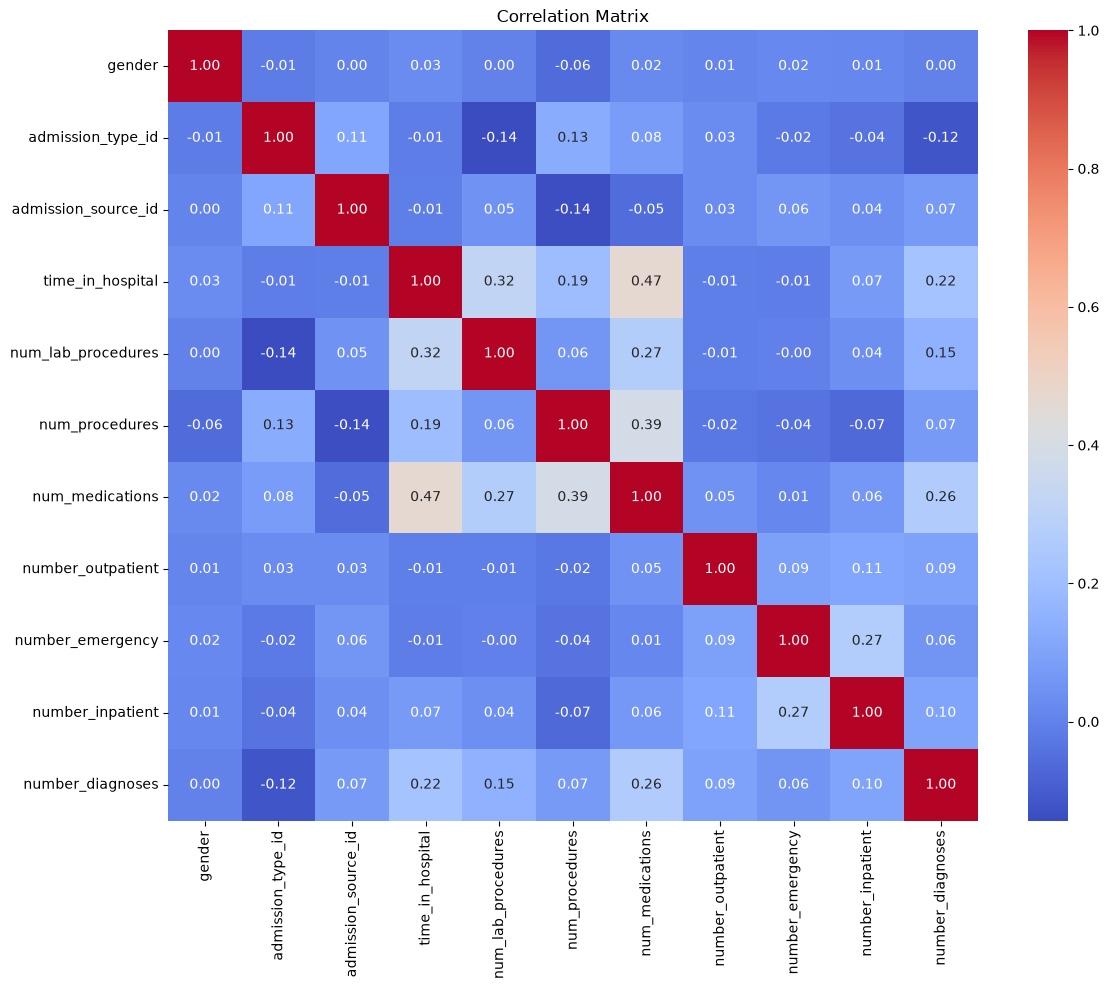

In [ ]:
#Correlation Matrix
plt.figure(figsize=(12,10))
numeric_data = diabetic_data_4.select_dtypes(include='number').drop(columns='patient_nbr', errors='ignore')
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')


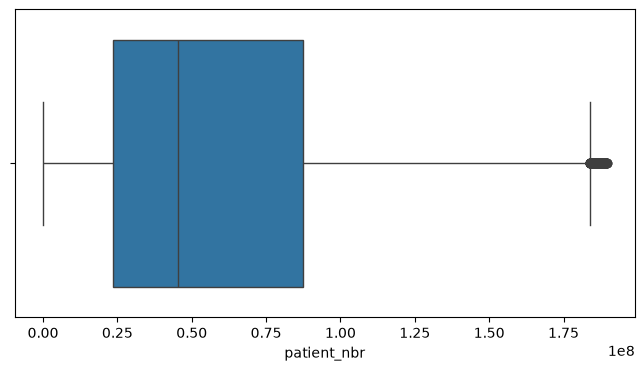

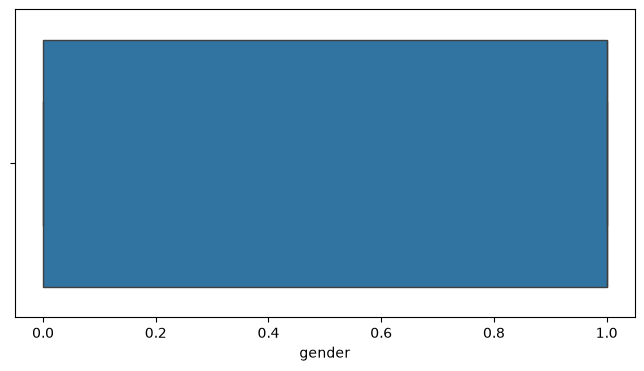

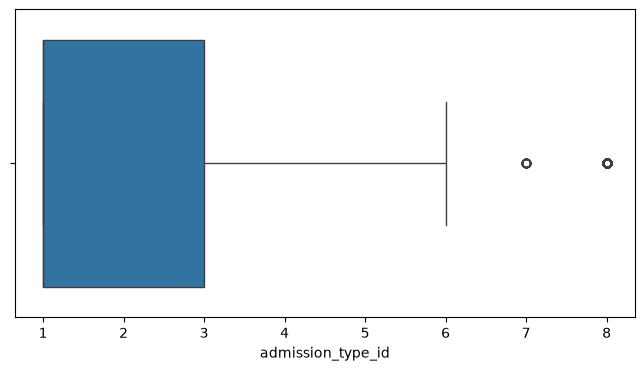

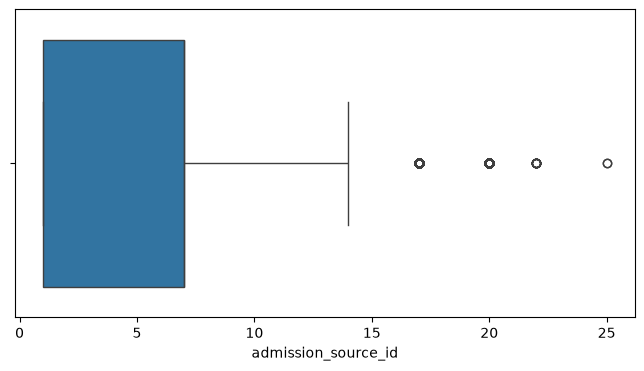

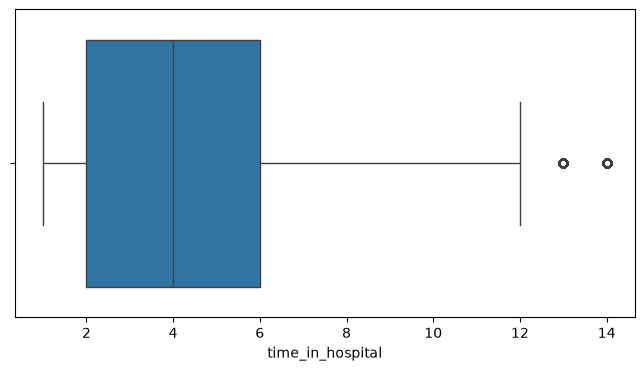

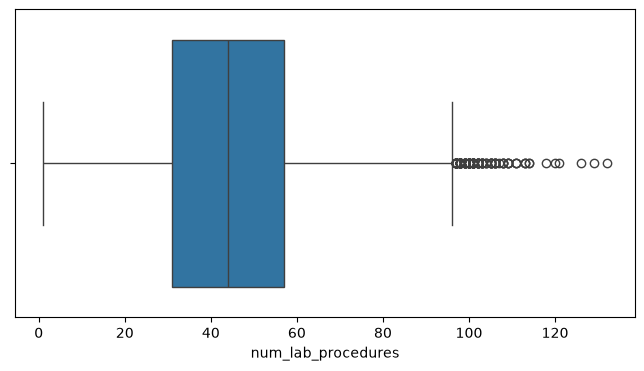

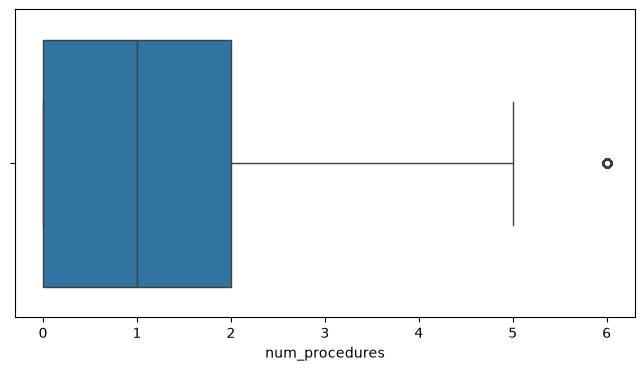

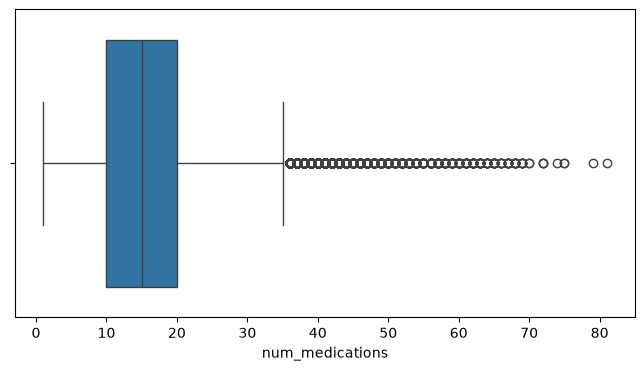

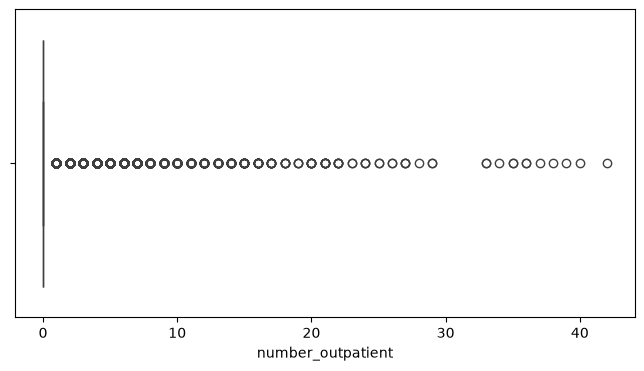

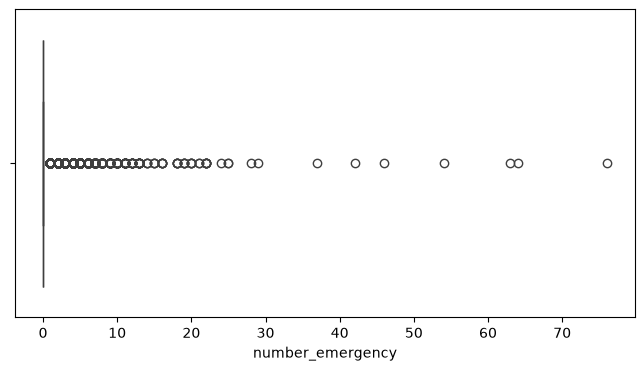

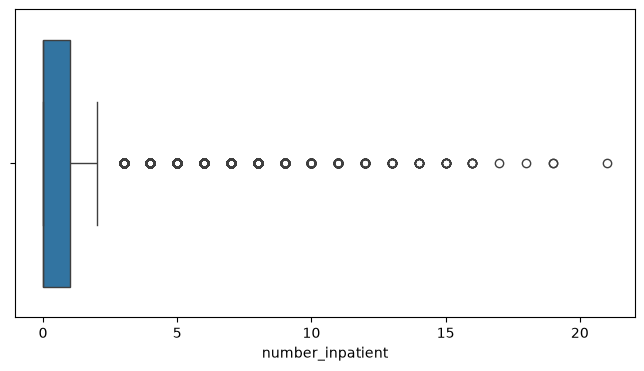

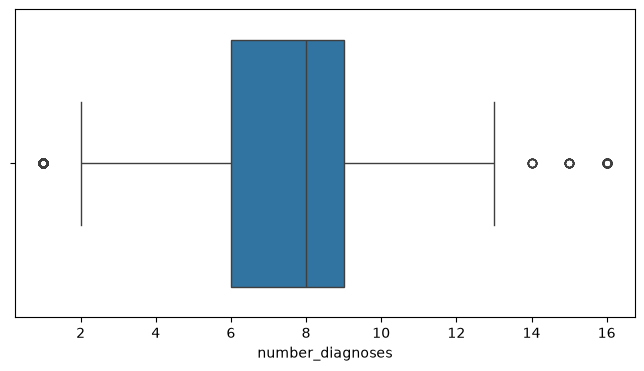

In [ ]:
numerical_columns = diabetic_data_4.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numerical_columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=diabetic_data_4[col])



<h1>Logistic Regression</h1>

Accuracy: 0.8328

Classification Report:
              precision    recall  f1-score   support

          >7       0.00      0.00      0.00       763
          >8       0.00      0.00      0.00      1643
        None       0.83      1.00      0.91     16949
        Norm       0.00      0.00      0.00       998

    accuracy                           0.83     20353
   macro avg       0.21      0.25      0.23     20353
weighted avg       0.69      0.83      0.76     20353



c:\Users\kaanb\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\kaanb\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\kaanb\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


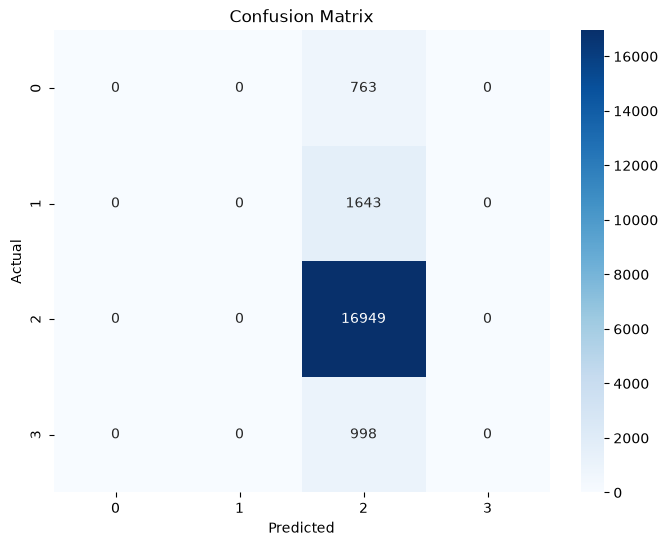

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#Split the data
# Predict A1C result from time in hospital
X = diabetic_data_4[['time_in_hospital']]
y = diabetic_data_4['A1Cresult']

# Remove rows with missing target values
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize using training data only
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#Time in hospital based on a1c result

#Standardize
scaler = StandardScaler()

#Create train model
sk_model = LogisticRegression(max_iter=1000)
sk_model.fit(X_train, y_train)

#Make predictions
y_pred = sk_model.predict(X_test)
y_prob = sk_model.predict_proba(X_test)[:, 1]

#Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred))

#Plot Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()



<h1>Inspecting the dataset<h1>

Looking at the type of variable each column represents

In [ ]:
print(diabetic_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

We look at the descriptive statistics of the data - this can help us see how the different varaibles behave

In [ ]:
print(diabetic_data.describe())

       encounter_id   patient_nbr  admission_type_id  \
count  1.017660e+05  1.017660e+05      101766.000000   
mean   1.652016e+08  5.433040e+07           2.024006   
std    1.026403e+08  3.869636e+07           1.445403   
min    1.252200e+04  1.350000e+02           1.000000   
25%    8.496119e+07  2.341322e+07           1.000000   
50%    1.523890e+08  4.550514e+07           1.000000   
75%    2.302709e+08  8.754595e+07           3.000000   
max    4.438672e+08  1.895026e+08           8.000000   

       discharge_disposition_id  admission_source_id  time_in_hospital  \
count             101766.000000        101766.000000     101766.000000   
mean                   3.715642             5.754437          4.395987   
std                    5.280166             4.064081          2.985108   
min                    1.000000             1.000000          1.000000   
25%                    1.000000             1.000000          2.000000   
50%                    1.000000             7.00000

<h2>Grouping the diag_1 variable and dropping diag_2, diag_3 and number_diagnoses<h2>

As the diag_1 shows the primary diagnosis accredited for the stay of the patient, we assume this diagnosis is placed during the admission of the patient to the hospital. In this way this would be data that would be avaivable to the scheduling office at the hospital when the patient is addmited.

Doing this also helps simplify the model, so it does not overfit.

In [6]:
# Defines the buckets for the diag_1 values
d1_bucket_def = {
    1: "Infectious and Parasitic Diseases",
    140: "Neoplasms",
    240: "Endocrine, Nutritional and Metabolic Diseases, and Immunity Disorders",
    280: "Diseases of the Blood and Blood-forming Organs",
    290: "Mental Disorders",
    320: "Diseases of the Nervous System and Sense Organs",
    390: "Diseases of the Circulatory System",
    460: "Diseases of the Respiratory System",
    520: "Diseases of the Digestive System",
    580: "Diseases of the Genitourinary System",
    630: "Complications of Pregnancy, Childbirth, and the Puerperium",
    680: "Diseases of the Skin and Subcutaneous Tissue",
    710: "Diseases of the Musculoskeletal System and Connective Tissue",
    740: "Congenital Anomalies",
    760: "Certain Conditions Originating in the Perinatal Period",
    780: "Symptoms, Signs, and Ill-defined Conditions",
    800: "Injury and Poisoning",
}

# Extracts and converts the variable data into a string, drops white spaces and upparcases all letters
codes = df["diag_1"].astype("string").str.strip().str.upper()

# Extract the numeric value before the dot using a regex. An "8" is seen as "008". Requires digits as an input and gives missing values if it gets a letters or symbols a part form "."
numeric_category = pd.to_numeric(
    codes.str.extract(r"^([0-9]{1,3})(?:\.[0-9]+)?$", expand=False),
    errors="coerce",
)

# assigns a new column to df, by comparing the extracted number to the buckets, and then outputing the name of the bucket
df["diag_1_category"] = pd.cut(
    numeric_category,
    bins=[*d1_bucket_def, 1000],
    labels=list(d1_bucket_def.values()),
    right=False,
).astype("string")

# Assign the supplementary codes by prefix.
df.loc[codes.str.startswith("E", na=False), "diag_1_category"] = (
    "External Causes of Injury and Poisoning"
)
df.loc[codes.str.startswith("V", na=False), "diag_1_category"] = (
    "Factors Influencing Health Status and Contact with Health Services"
)

print(df["diag_1_category"].value_counts(dropna=False))

#overwrites the old diag_1 values
df['diag_1'] = df["diag_1_category"]


KeyError: 'diag_1'

The variable now contains 19 distinct values one of which is NA, the others are descriptors of categories of diagnosies.

We drop diag_2, diag_3 and number_diagnoses because we cannot assume at what point these diagnosis were placed, thus this data might not be avaibale at the time of the model's real world use.

In [4]:
df = df.drop(columns = ['diag_2','diag_3','number_diagnoses'])

Rename the diag_1 column

In [ ]:
df = df.rename(columns={'diag_1' : 'diag_cat'})

In [ ]:
df